# Fourier transform spectroscopy: interferograms, apodization and the multiplex advantage

A Michelson interferometer with a moving mirror turns a spectrum into a
signal in time. Each wavenumber $\tilde\nu = 1/\lambda$ makes fringes
$1 + \cos(2\pi\tilde\nu x)$ as the optical path difference $x$ grows, and
the detector sees the sum of all of them: the **interferogram**, the
cosine transform of the spectrum. Notebook 74 (coherence and stellar interferometry) used this to explain
temporal coherence and resolved the sodium doublet with a 2 mm scan. This
notebook builds the instrument that made it a laboratory standard, the
Fourier transform infrared (FTIR) spectrometer, and asks what limits it:

1. the interferogram of a hot source seen through an absorbing gas,
   with its centre burst and the faint beats of the gas lines far out,
2. resolution and the instrument line shape: the sinc of a finite
   scan, its ringing, apodization windows and what zero filling does
   (and does not) do,
3. sampling with a helium–neon reference laser: the Nyquist limit,
   aliasing, and the ghosts of an uneven mirror drive,
4. phase correction: an asymmetric interferogram from a dispersive beam
   splitter and an off-centre zero path difference, corrected after Mertz,
5. the aperture: off-axis rays see a shorter path difference, the
   Jacquinot stop and self-apodization, ray traced against the closed form,
6. the Jacquinot (étendue) and Fellgett (multiplex) advantages against a
   grating spectrometer, with numbers and with Monte Carlo noise.

Wavenumbers are in cm⁻¹, path differences in cm. The functions are in
`pyoptics.spectroscopy` (interferograms, apodization, instrument line
shapes, Mertz correction, line lists of a model band).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import hilbert

from pyoptics import radiometry as rad
from pyoptics import spectroscopy as spc
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(111)

## 1. The interferogram

A Michelson splits the beam, delays one half by the optical path
difference $x$ and recombines them. For a single wavenumber the detector
sees $\frac12 S(1 + \cos 2\pi\tilde\nu x)$; the wavenumbers of a thermal
source are mutually incoherent, so their intensities add:

$$I(x) = \tfrac12\int_0^\infty S(\tilde\nu)\,d\tilde\nu
  + \tfrac12\int_0^\infty S(\tilde\nu)\cos(2\pi\tilde\nu x)\,d\tilde\nu .$$

The constant part carries no spectral information; the modulated part is
the cosine transform of $S$ and gives it back by the inverse transform.
The source is a 1200 K glowing rod (a "globar", `radiometry.planck_radiance()`)
seen through a cell with carbon dioxide, which absorbs in its
asymmetric stretching band at 2349 cm⁻¹ (4.26 µm), and through the
transmission of a KBr beam splitter and a detector, modelled as a smooth
band from about 500 to 6000 cm⁻¹.

The CO₂ band is a model, not a database (`spectroscopy.linear_molecule_band()`):
a rigid rotor with $B = 0.390$ cm⁻¹, P and R branches, Boltzmann
populations at 296 K and only the even rotational levels of the ground
state (the two oxygen nuclei are identical bosons), so the lines are
$4B \approx 1.56$ cm⁻¹ apart. Each line is a Lorentzian of 0.14 cm⁻¹ FWHM
(air broadened at 1 atm). Notebook 114 (spectral lines and absorption) looks at such bands in detail.

To compute interferograms of lines much narrower than the resolution,
the true spectrum is sampled on a fine grid of 0.004 cm⁻¹ and transformed
with an FFT. That gives the interferogram out to ±125 cm of path
difference, of which the instrument records only a part.

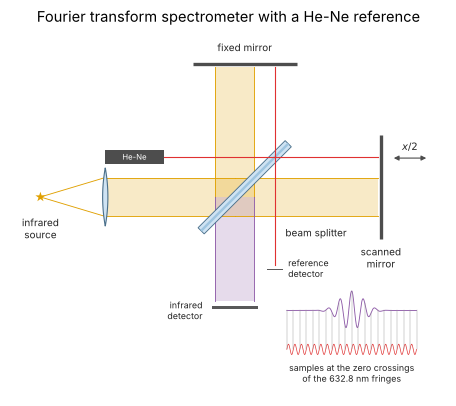

In [2]:
fig, ax = plt.subplots(figsize=(8, 6))
sketch.fts_layout(ax, "michelson", title="Fourier transform spectrometer with a He-Ne reference")
plt.show()

fine grid: Δν = 0.0038 cm⁻¹, Nyquist 7899.0 cm⁻¹, period in x 265 cm


strongest CO2 line: optical depth 21.2, the band is 91 lines


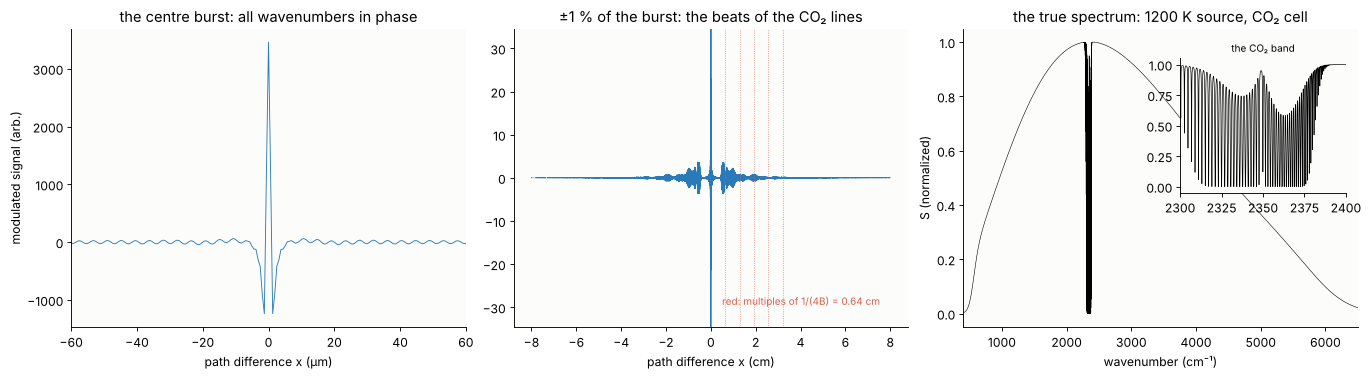

centre burst: 90 % of the burst height is gone by x = 3.2 µm


In [3]:
NU_HENE = 15798.0                         # cm^-1, vacuum wavenumber of the He-Ne laser
DX = 1/NU_HENE                            # sampling once per laser fringe (cm)
N_FINE = 2**22                            # FFT length for the "true" interferogram
nu_f = np.fft.rfftfreq(N_FINE, DX)        # wavenumber grid (cm^-1), 0 ... 7899
dnu_f = nu_f[1]
x_f = np.arange(N_FINE)*DX                # path differences 0 ... 265 cm (periodic)
print("fine grid: Δν = {:.4f} cm⁻¹, Nyquist {:.1f} cm⁻¹, period in x {:.0f} cm".format(
    dnu_f, nu_f[-1], N_FINE*DX))

lam_nm = 1e7/np.maximum(nu_f, 1.0)
source = rad.planck_radiance(lam_nm, 1200.0)*lam_nm**2/1e7          # per cm^-1
optics = 1/(1 + np.exp(-(nu_f - 550)/40))/(1 + np.exp((nu_f - 6000)/300))
pos, S_lines, labels = spc.linear_molecule_band(2349.14, 0.39022, 0.38714, 296.0,
                                                J_max=90, even_only=True)
sigma = spc.line_list_spectrum(nu_f, pos, S_lines, 0.0, 0.14)       # 1/cm^-1, area 1 in total
tau_co2 = 120.0*sigma                                                # optical depth of the cell
S_true = source*optics*spc.transmittance(tau_co2)
S_true /= S_true.max()
print("strongest CO2 line: optical depth {:.1f}, the band is {:.0f} lines".format(tau_co2.max(), len(pos)))


def interferogram_from(S):
    """Modulated interferogram (the cosine transform), x = 0, DX, 2 DX, ..."""
    return 0.5*np.fft.irfft(S, N_FINE)*N_FINE*dnu_f     # irfft doubles the k > 0 terms


I_true = interferogram_from(S_true)


def two_sided(I, L):
    """Samples of the symmetric interferogram for |x| <= L."""
    n = int(round(L/DX))
    x = np.arange(-n, n + 1)*DX
    return x, np.concatenate([I[n:0:-1], I[:n + 1]])


x8, I8 = two_sided(I_true, 8.0)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ax[0].plot(x8*1e4, I8, color=BLUE, lw=0.8)
ax[0].set_xlim(-60, 60)
ax[0].set_xlabel("path difference x (µm)")
ax[0].set_ylabel("modulated signal (arb.)")
ax[0].set_title("the centre burst: all wavenumbers in phase")
ax[1].plot(x8, I8, color=BLUE, lw=0.4)
ax[1].set_ylim(-0.01*I8.max(), 0.01*I8.max())
for k in (1, 2, 3, 4, 5):
    ax[1].axvline(k/(4*0.3902), color=RED, lw=0.6, ls=":")
ax[1].set_xlabel("path difference x (cm)")
ax[1].set_title("±1 % of the burst: the beats of the CO₂ lines")
ax[1].text(0.5, -0.0085*I8.max(), "red: multiples of 1/(4B) = 0.64 cm", color=RED, fontsize=9)
ax[2].plot(nu_f, S_true, color="k", lw=0.5)
ax[2].set_xlim(400, 6500)
ax[2].set_xlabel("wavenumber (cm⁻¹)")
ax[2].set_ylabel("S (normalized)")
ax[2].set_title("the true spectrum: 1200 K source, CO₂ cell")
ins = ax[2].inset_axes([0.55, 0.45, 0.42, 0.45])
ins.plot(nu_f, S_true, color="k", lw=0.6)
ins.set_xlim(2300, 2400)
ins.set_title("the CO₂ band", fontsize=9)
plt.show()
print("centre burst: {:.0f} % of the burst height is gone by x = {:.1f} µm".format(
    90, x8[np.argmax(np.abs(I8[len(I8)//2:]) < 0.1*I8.max()) + len(I8)//2]*1e4))

Near $x = 0$ all wavenumbers are in phase and add up to the **centre
burst**. A few µm away their fringes have run out of step, and the
interferogram drops to a few per cent of the burst. The width of the
burst is about the inverse width of the spectrum, a few µm for a band of
several thousand cm⁻¹, which is the white-light coherence length of notebook 74 (coherence and stellar interferometry).
The spectral detail lives far out, at a level of a per cent. The CO₂
lines form a comb with the spacing $4B$, whose interferogram is a train of
echoes at multiples of $1/(4B) = 0.64$ cm, each smeared by the
change of the line spacing across the band. Resolving lines means
recording these weak echoes, which is why the dynamic range of the
detector and its digitizer is a central design problem of an FTIR:
the burst is a hundred times stronger than the information.

## 2. Resolution and the instrument line shape

The instrument records the interferogram only for $|x| \le L$, i.e. the
true one times a window $A(x/L)$. By the convolution theorem the measured
spectrum is the true one convolved with the transform of the window,
the **instrument line shape** (ILS). For a plain cut (boxcar) it is

$$\mathrm{ILS}(\tilde\nu) = 2L\,\mathrm{sinc}(2\tilde\nu L),$$

with a FWHM of $1.207/(2L)$ and side lobes of −22 %: a sharp line is
surrounded by negative ripples. **Apodization** ("removing the feet")
multiplies the interferogram with a window that falls smoothly to zero at
$L$ and trades resolution for weaker side lobes. `spectroscopy.apodization()`
has the triangle, Happ–Genzel, the three Norton–Beer windows (designed
to give the least broadening for a given side lobe) and Blackman–Harris.
The nominal resolution of an instrument is quoted as $1/L$ or $1/(2L)$
depending on the manufacturer; the FWHM of the ILS is what counts.

window               FWHM × 2L   largest negative lobe
boxcar                  1.207    -0.217
triangle                1.772    -0.000
happ_genzel             1.815    -0.007
norton_beer_weak        1.448    -0.058
norton_beer_medium      1.689    -0.014
norton_beer_strong      1.931    -0.004
blackman_harris         2.274    -0.000


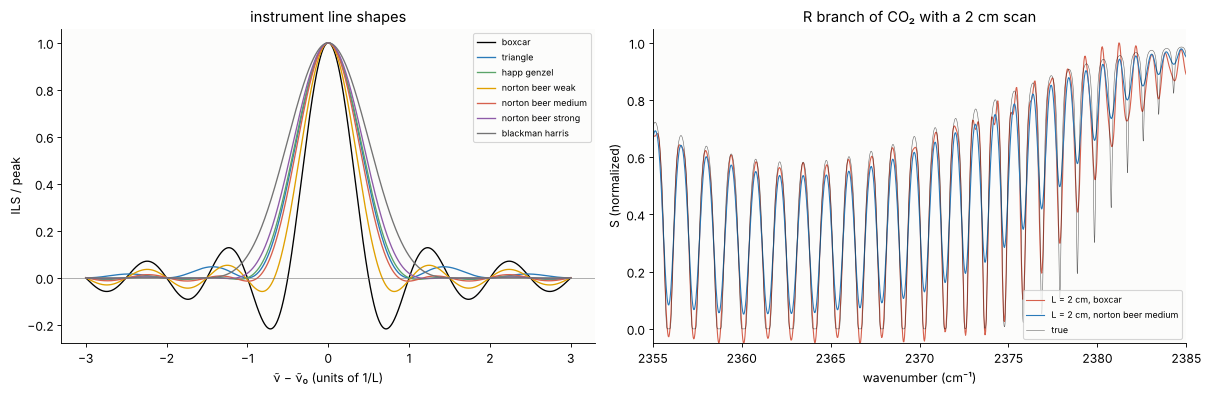

In [4]:
nu_ils = np.linspace(-3, 3, 3001)
L = 1.0
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
rows = []
for kind, c in zip(spc.APODIZATIONS, ("k", BLUE, GREEN, ORANGE, RED, PURPLE, GREY)):
    ils = spc.instrument_line_shape(nu_ils, L, kind)
    ax[0].plot(nu_ils, ils/ils.max(), color=c, lw=1.2, label=kind.replace("_", " "))
    rows.append((kind, spc.fwhm(nu_ils, ils)*2*L, ils.min()/ils.max()))
ax[0].axhline(0, color=GREY, lw=0.5)
ax[0].set_xlabel("ν̃ − ν̃₀ (units of 1/L)")
ax[0].set_ylabel("ILS / peak")
ax[0].set_title("instrument line shapes")
ax[0].legend(fontsize=8)
print("window               FWHM × 2L   largest negative lobe")
for kind, w, m in rows:
    print("{:20s} {:8.3f}    {:+.3f}".format(kind, w, m))

# the CO2 band at two resolutions, boxcar against Norton-Beer medium
for Lr, ls in ((0.5, "-"), (4.0, "-")):
    pass
for kind, c in (("boxcar", RED), ("norton_beer_medium", BLUE)):
    x, I = two_sided(I_true, 2.0)
    nu, S = spc.fts_spectrum(x, I, kind, n_fft=8*len(x))
    ax[1].plot(nu, S/np.max(S[(nu > 2000) & (nu < 2700)]), color=c, lw=1,
               label="L = 2 cm, " + kind.replace("_", " "))
sel = (nu_f > 2300) & (nu_f < 2400)
ax[1].plot(nu_f[sel], S_true[sel]/np.max(S_true[(nu_f > 2000) & (nu_f < 2700)]), color="k", lw=0.5,
           alpha=0.6, label="true")
ax[1].set_xlim(2355, 2385)
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xlabel("wavenumber (cm⁻¹)")
ax[1].set_ylabel("S (normalized)")
ax[1].set_title("R branch of CO₂ with a 2 cm scan")
ax[1].legend(fontsize=8, loc="lower right")
plt.show()

The FWHM of the line shapes, in units of $1/(2L)$, and their largest
negative lobe are those published by Norton and Beer: 1.207 and −22 % for
the boxcar, 1.69 and −1.4 % for Norton–Beer medium, 1.77 and no negative
lobe for the triangle. In the CO₂ band, scanned to $L = 2$ cm, the boxcar
reaches deeper into the lines but overshoots below zero next to the
strong ones, and puts ripples on the continuum (an absorbance below zero
or a transmittance above 1 is a typical boxcar artefact). Norton–Beer medium
gives smooth, slightly shallower lines. Every quantitative comparison of
spectra must use the same apodization.

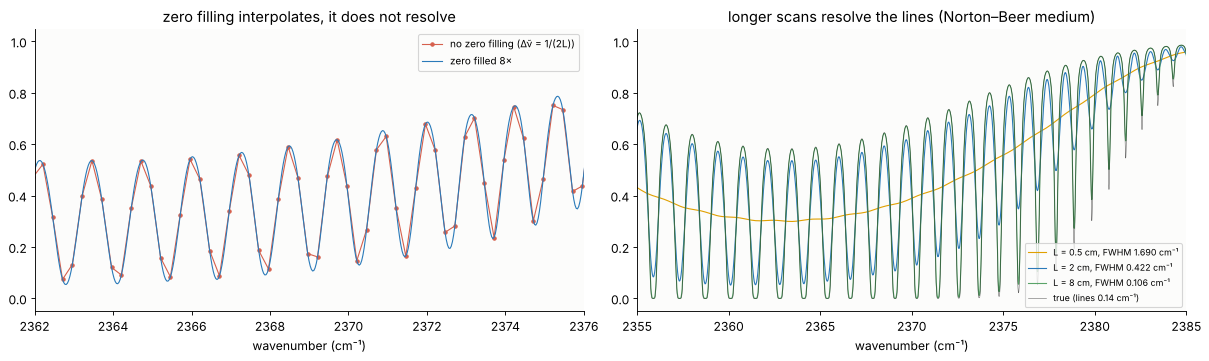

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
x, I = two_sided(I_true, 2.0)
for nf, c, lab in ((1, RED, "no zero filling (Δν̃ = 1/(2L))"), (8, BLUE, "zero filled 8×")):
    nu, S = spc.fts_spectrum(x, I, "norton_beer_medium", n_fft=nf*len(x))
    ax[0].plot(nu, S/np.max(S[(nu > 2000) & (nu < 2700)]), "o-" if nf == 1 else "-", ms=3, color=c,
               lw=1, label=lab)
ax[0].set_xlim(2362, 2376)
ax[0].set_ylim(-0.05, 1.05)
ax[0].set_xlabel("wavenumber (cm⁻¹)")
ax[0].set_title("zero filling interpolates, it does not resolve")
ax[0].legend(fontsize=9)
for Lr, c in ((0.5, ORANGE), (2.0, BLUE), (8.0, GREEN)):
    x, I = two_sided(I_true, Lr)
    nu, S = spc.fts_spectrum(x, I, "norton_beer_medium", n_fft=max(8*len(x), 2**16))
    ax[1].plot(nu, S/np.max(S[(nu > 2000) & (nu < 2700)]), color=c, lw=1,
               label="L = {:g} cm, FWHM {:.3f} cm⁻¹".format(Lr, 1.69/(2*Lr)))
ax[1].plot(nu_f, S_true/np.max(S_true[(nu_f > 2000) & (nu_f < 2700)]), color="k", lw=0.5, alpha=0.6,
           label="true (lines 0.14 cm⁻¹)")
ax[1].set_xlim(2355, 2385)
ax[1].set_ylim(-0.05, 1.05)
ax[1].set_xlabel("wavenumber (cm⁻¹)")
ax[1].set_title("longer scans resolve the lines (Norton–Beer medium)")
ax[1].legend(fontsize=8, loc="lower right")
plt.show()

The FFT of $n$ samples gives spectral samples $1/(n\,\Delta x) = 1/(2L)$
apart, about as far apart as the resolution. Zero filling (padding the
interferogram with zeros before the FFT) gives more samples of the *same*
spectrum, as the smooth blue curve through the red points shows; it is a
sinc interpolation, which finds line positions and depths that coarse
samples miss, but it does not resolve anything new. Only a longer scan does
that: with $L = 0.5$ cm (FWHM 1.7 cm⁻¹) the band is a smooth trough, with
2 cm (0.42 cm⁻¹) the lines appear with reduced depth, and with 8 cm
(0.11 cm⁻¹, below the line width of 0.14 cm⁻¹) they reach almost their
true depth. Laboratory FTIRs scan a few cm; the high-resolution
instruments of molecular spectroscopy scan several metres.

## 3. Sampling with a laser reference

The interferogram has to be sampled at exactly known path differences.
Every FTIR sends a helium–neon laser (632.99 nm in vacuum, 15 798 cm⁻¹)
through the same interferometer: its fringes are a ruler of the mirror
position, and the detector is read at its zero crossings or once per
fringe. Sampling every $\Delta x = \lambda_\mathrm{HeNe}$ sets the Nyquist
limit

$$\tilde\nu_\mathrm{max} = \frac{1}{2\Delta x} = 7899\ \mathrm{cm^{-1}},$$

enough for the mid infrared. Light above it is folded back
(aliased): a near infrared line at 9000 cm⁻¹ appears at
$2\cdot 7899 - 9000 = 6798$ cm⁻¹, so an optical low-pass filter (or the
detector's cut-off) must block it. Reading at both zero crossings
doubles the limit to 15 798 cm⁻¹ for the near infrared and visible.

Mirror drives are not perfect. If the samples were taken at equal
*times* instead of laser fringes, a periodic error of the mirror
velocity would shift the sample positions by $a\sin(2\pi x/\Lambda)$,
phase modulating every fringe: each line gets **ghosts** at
$\tilde\nu \pm 1/\Lambda$ with the relative amplitude $\pi\tilde\nu a$.

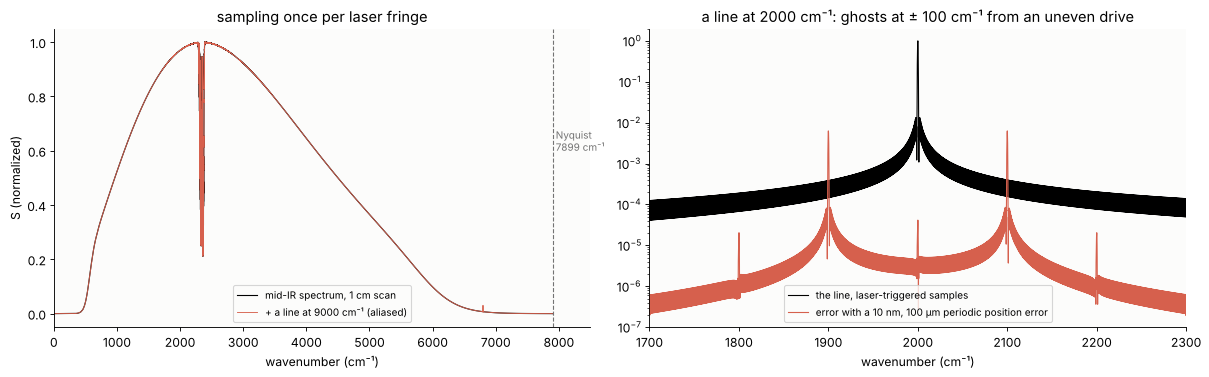

aliased line found at 6798.0 cm⁻¹ (expected 6798.0)
ghost of the line at 2000 -100 cm⁻¹: 6.29e-03 of the line, π ν̃ a = 6.28e-03
ghost of the line at 2000 +100 cm⁻¹: 6.29e-03 of the line, π ν̃ a = 6.28e-03


In [6]:
x, I = two_sided(I_true, 1.0)
# a narrow near-infrared line beyond the Nyquist limit, sampled at the laser fringes:
x_alias = np.arange(-int(1.0/DX), int(1.0/DX) + 1)*DX
I_nir = 0.02*np.cos(2*np.pi*9000.0*x_alias)
nu_a, S_a = spc.fts_spectrum(x_alias, I + I_nir, "norton_beer_medium", n_fft=4*len(x_alias))
nu_0, S_0 = spc.fts_spectrum(x, I, "norton_beer_medium", n_fft=4*len(x))
# sampling error: periodic position error a sin(2 pi x / Lambda), seen on a narrow
# emission line at 2000 cm^-1 on top of the continuum
a_err, Lam = 10e-7, 0.01                 # 10 nm amplitude, 100 µm period (100 cm^-1 ghosts)
xs = x + a_err*np.sin(2*np.pi*x/Lam)     # where the samples were really taken
line = lambda xx: 0.05*np.cos(2*np.pi*2000.0*xx)
I_line = I + line(x)
I_line_j = np.interp(xs, x, I) + line(xs)  # the continuum is smooth on the scale of a
nu_l, S_l = spc.fts_spectrum(x, I_line, "norton_beer_medium", n_fft=4*len(x))
nu_j, S_j = spc.fts_spectrum(x, I_line_j, "norton_beer_medium", n_fft=4*len(x))
# the line alone, to measure its ghosts:
nu_1, S_1 = spc.fts_spectrum(x, line(x), "norton_beer_medium", n_fft=4*len(x))
_, S_1j = spc.fts_spectrum(x, line(xs), "norton_beer_medium", n_fft=4*len(x))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
ax[0].plot(nu_0, S_0/S_0.max(), color="k", lw=1, label="mid-IR spectrum, 1 cm scan")
ax[0].plot(nu_a, S_a/S_0.max(), color=RED, lw=0.8,
           label="+ a line at 9000 cm⁻¹ (aliased)")
ax[0].axvline(7899, color=GREY, ls="--", lw=1)
ax[0].text(7950, 0.6, "Nyquist\n7899 cm⁻¹", color=GREY, fontsize=9)
ax[0].set_xlim(0, 8500)
ax[0].set_xlabel("wavenumber (cm⁻¹)")
ax[0].set_ylabel("S (normalized)")
ax[0].set_title("sampling once per laser fringe")
ax[0].legend(fontsize=9)
ax[1].semilogy(nu_1, np.abs(S_1)/S_1.max(), color="k", lw=1, label="the line, laser-triggered samples")
ax[1].semilogy(nu_1, np.abs(S_1j - S_1)/S_1.max(), color=RED, lw=1,
               label="error with a 10 nm, 100 µm periodic position error")
ax[1].set_xlim(1700, 2300)
ax[1].set_ylim(1e-7, 2)
ax[1].set_xlabel("wavenumber (cm⁻¹)")
ax[1].set_title("a line at 2000 cm⁻¹: ghosts at ± 100 cm⁻¹ from an uneven drive")
ax[1].legend(fontsize=9)
plt.show()
k_alias = np.argmax(np.where((nu_a > 6000) & (nu_a < 7899), S_a - np.interp(nu_a, nu_0, S_0), 0))
print("aliased line found at {:.1f} cm⁻¹ (expected {:.1f})".format(nu_a[k_alias], 2*NU_HENE/2 - 9000))
for off in (-100, 100):
    i_g = np.argmin(np.abs(nu_1 - (2000.0 + off)))
    print("ghost of the line at 2000 {:+d} cm⁻¹: {:.2e} of the line, π ν̃ a = {:.2e}".format(
        off, np.abs(S_1j - S_1)[i_g - 5:i_g + 6].max()/S_1.max(), np.pi*2000.0*a_err))

With samples once per laser fringe the spectrum ends at 7899 cm⁻¹. A
line at 9000 cm⁻¹ appears exactly at 6798 cm⁻¹, as a false line in the
near infrared. A periodic position error of only 10 nm (1/60 of a sample
spacing) with a period of 100 µm puts ghosts of each line at
±100 cm⁻¹, with the relative amplitude $6.3\times10^{-3}$, as predicted by
$\pi\tilde\nu a$. Ghosts grow with the wavenumber, so they matter most
in the near infrared and visible. Triggering the samples by the laser
fringes removes the position error, leaving only the timing jitter of the
electronics, which is why the reference laser became the heart of every
FTIR. The precision of the laser wavelength also makes the wavenumber scale
of an FTIR accurate to better than 0.01 cm⁻¹ without any calibration
(Connes' advantage).

## 4. Phase correction

Real interferograms are not symmetric. The zero path difference is not
exactly at a sample, and the beam splitter (a KBr plate with a
germanium coating, and a compensator plate that never matches it
perfectly) adds a phase $\phi(\tilde\nu)$ that changes with the
wavenumber. The interferogram becomes $\int S\cos(2\pi\tilde\nu x + \phi)\,d\tilde\nu$,
and its cosine transform is $S\cos\phi$: wrong, and negative where
$\phi > 90°$. The magnitude of the complex transform, $|S|$, has the right
shape but turns noise into a positive bias.

Most instruments record **one-sided** interferograms (from $-L_\phi$ to
$L$ with $L_\phi \ll L$) to get twice the resolution for the same scan
length. Mertz's method takes the phase from the short double-sided part,
where it is smooth and can be computed at low resolution, and removes it
from the complex spectrum of the whole scan, weighted with a ramp so that
the part measured twice counts once (`spectroscopy.mertz_spectrum()`).
Below: a ZPD half a sample off, a constant phase of 0.3 rad and a
quadratic phase of 2 rad across the band from an unmatched compensator.

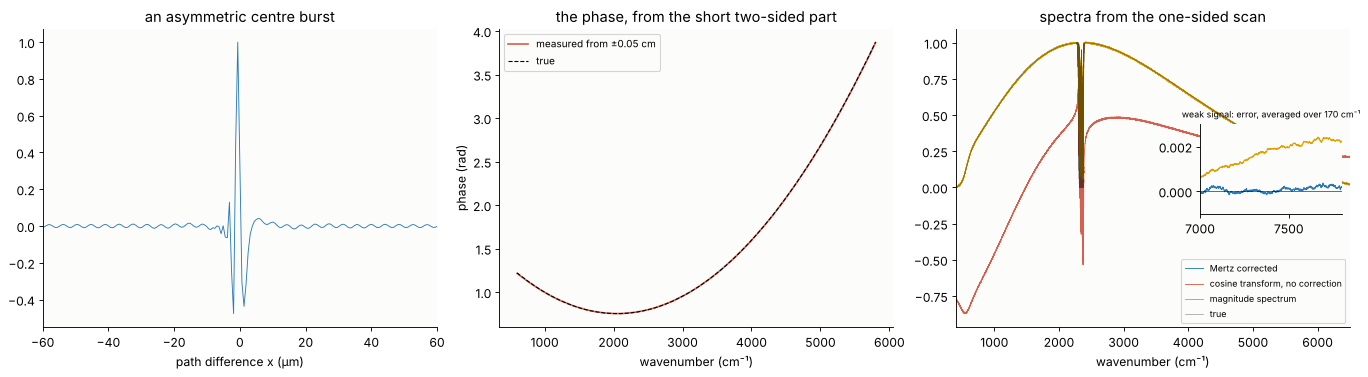

where the signal is weak (7000-7850 cm⁻¹): mean error Mertz +8.4e-05, magnitude +1.7e-03 (noise rms 2.1e-03)
continuum 3000-5000 cm⁻¹: Mertz/true − 1 = -2.8e-03 ± 3.5e-03, uncorrected cosine transform/true − 1 = -0.40


In [7]:
phase_true = 0.3 + 2*np.pi*nu_f*0.5*DX + 2.0*((nu_f - 2500)/3000)**2
I_ph = 0.5*np.fft.irfft(S_true*np.exp(1j*phase_true), N_FINE)*N_FINE*dnu_f   # sum S cos(2πνx + φ)
n_neg, n_pos = int(0.05/DX), int(2.0/DX)
xo = np.arange(-n_neg, n_pos + 1)*DX
Io = np.concatenate([I_ph[-n_neg:], I_ph[:n_pos + 1]])
noise = 3e-5*np.abs(Io).max()
Io_n = Io + noise*rng.standard_normal(len(Io))
nu_m, S_m, ph_m = spc.mertz_spectrum(xo, Io_n, 0.05, kind="norton_beer_medium")
# the naive cosine transform of the "symmetrized" one-sided interferogram (treat it as symmetric):
x_naive = np.arange(-n_pos, n_pos + 1)*DX
I_naive = np.concatenate([Io_n[n_neg + 1:][::-1], Io_n[n_neg:]])
nu_c, S_c = spc.fts_spectrum(x_naive, I_naive, "norton_beer_medium", n_fft=2*len(nu_m) - 2)
# magnitude spectrum (complex FFT of the one-sided record, with the same ramp):
ramp = np.clip((xo + 0.05)/(2*0.05), 0, 1)
buf = np.zeros(2*len(nu_m) - 2)
buf[:n_pos + 1] = (Io_n*ramp*spc.apodization(xo, xo.max(), "norton_beer_medium"))[n_neg:]
buf[-n_neg:] = (Io_n*ramp*spc.apodization(xo, xo.max(), "norton_beer_medium"))[:n_neg]
S_mag = 4*np.abs(np.fft.rfft(buf))*DX
ref = np.interp(nu_m, nu_f, S_true)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
ax[0].plot(xo*1e4, Io/np.abs(Io).max(), color=BLUE, lw=0.8)
ax[0].set_xlim(-60, 60)
ax[0].set_xlabel("path difference x (µm)")
ax[0].set_title("an asymmetric centre burst")
band = (nu_m > 600) & (nu_m < 5800)
ax[1].plot(nu_m[band], np.unwrap(ph_m[band]) - 2*np.pi*np.round(np.unwrap(ph_m[band])[0]/(2*np.pi)),
           color=RED, label="measured from ±0.05 cm")
ax[1].plot(nu_f[(nu_f > 600) & (nu_f < 5800)], phase_true[(nu_f > 600) & (nu_f < 5800)], "k--", lw=1,
           label="true")
ax[1].set_xlabel("wavenumber (cm⁻¹)")
ax[1].set_ylabel("phase (rad)")
ax[1].set_title("the phase, from the short two-sided part")
ax[1].legend(fontsize=9)
ax[2].plot(nu_m, S_m/ref.max(), color=BLUE, lw=0.8, label="Mertz corrected")
ax[2].plot(nu_c, S_c/ref.max(), color=RED, lw=0.8, label="cosine transform, no correction")
ax[2].plot(nu_m, S_mag/ref.max(), color=ORANGE, lw=0.8, label="magnitude spectrum")
ax[2].plot(nu_f, S_true/ref.max(), color="k", lw=0.5, alpha=0.5, label="true")
ax[2].set_xlim(400, 6500)
ax[2].set_xlabel("wavenumber (cm⁻¹)")
ax[2].set_title("spectra from the one-sided scan")
ax[2].legend(fontsize=8)
ins = ax[2].inset_axes([0.62, 0.38, 0.36, 0.3])
box = np.ones(400)/400
for y, c in ((S_m, BLUE), (S_mag, ORANGE)):
    ins.plot(nu_m, np.convolve((y - ref)/ref.max(), box, mode="same"), color=c, lw=1)
ins.set_xlim(7000, 7800)
ins.set_ylim(-0.001, 0.003)
ins.axhline(0, color="k", lw=0.5)
ins.set_title("weak signal: error, averaged over 170 cm⁻¹", fontsize=8)
plt.show()
quiet = (nu_m > 7000) & (nu_m < 7850)
print("where the signal is weak (7000-7850 cm⁻¹): mean error Mertz {:+.1e}, magnitude {:+.1e} (noise rms {:.1e})".format(
    np.mean(S_m[quiet] - ref[quiet])/ref.max(), np.mean(S_mag[quiet] - ref[quiet])/ref.max(),
    S_m[quiet].std()/ref.max()))
smooth = (nu_m > 3000) & (nu_m < 5000)          # continuum without lines
print("continuum 3000-5000 cm⁻¹: Mertz/true − 1 = {:+.1e} ± {:.1e}, uncorrected cosine transform/true − 1 = {:+.2f}".format(
    np.mean(S_m[smooth]/ref[smooth] - 1), np.std(S_m[smooth]/ref[smooth] - 1),
    np.mean(np.interp(nu_m[smooth], nu_c, S_c)/ref[smooth] - 1)))

The phase measured from the 0.05 cm double-sided part follows the true
phase across the band (after removing the arbitrary multiple of $2\pi$).
The Mertz-corrected spectrum from the one-sided scan agrees with the true
spectrum to −0.3 % ± 0.4 % in the continuum, i.e. within its noise. The
uncorrected cosine transform is 40 % low there and negative below
1000 cm⁻¹, where the phase approaches $\pi/2$. The magnitude spectrum
has the right shape but is biased where the signal is weak, here by
$1.7\times10^{-3}$ of the peak against $8\times10^{-5}$ for Mertz,
almost the size of the noise. A magnitude spectrum turns zero-mean
noise into a positive floor, which matters for
quantitative absorbances. The ramp weighting is essential: without it the
double-sided part would be counted twice and the low wavenumbers (the
broad parts of the spectrum, which live near $x = 0$) would come out too high.

## 5. The aperture: the Jacquinot stop and self-apodization

A ray that crosses the interferometer at the angle $\theta$ to the axis
sees the path difference $x\cos\theta$, not $x$. Light from a source of
finite size fills a cone of half angle $\theta_m$ (solid angle
$\Omega = 2\pi(1 - \cos\theta_m) \approx \pi\theta_m^2$), and a line at
$\tilde\nu_0$ is seen as a band from $\tilde\nu_0\cos\theta_m$ to
$\tilde\nu_0$, uniformly filled because equal solid angles give equal
shifts. The line is shifted by $\tilde\nu_0\Omega/4\pi$ and broadened into
a rectangle of width $\tilde\nu_0\Omega/2\pi$, which multiplies the
interferogram with a sinc that falls to zero at $x = 2\pi/(\tilde\nu_0\Omega)$:
**self-apodization**. Keeping the broadening below the resolution
$\delta\tilde\nu$ limits the solid angle to

$$\Omega \le \frac{2\pi}{R},\qquad R = \tilde\nu/\delta\tilde\nu,$$

Jacquinot's criterion, set by a circular field stop (the "J-stop") in
the focus of the collimator. Below, rays fill the cone uniformly in
solid angle (Monte Carlo); each adds its own cosine with the path difference
$x\cos\theta$.

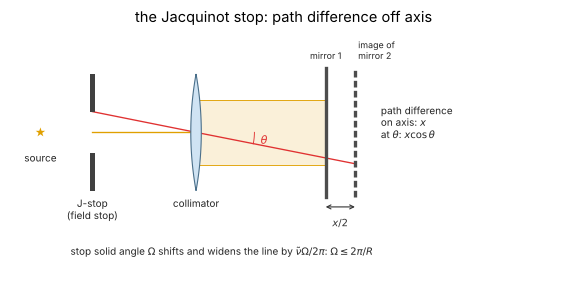

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
sketch.fts_layout(ax, "jacquinot", title="the Jacquinot stop: path difference off axis")
plt.show()

Ω = 0.5 × 2π/R: centroid shift -0.0747 cm⁻¹ (−ν̃Ω/4π = -0.0754), FWHM 0.309 cm⁻¹ (resolution 0.302)


Ω = 1 × 2π/R: centroid shift -0.1557 cm⁻¹ (−ν̃Ω/4π = -0.1509), FWHM 0.335 cm⁻¹ (resolution 0.302)


Ω = 3 × 2π/R: centroid shift -0.4639 cm⁻¹ (−ν̃Ω/4π = -0.4526), FWHM 0.852 cm⁻¹ (resolution 0.302)


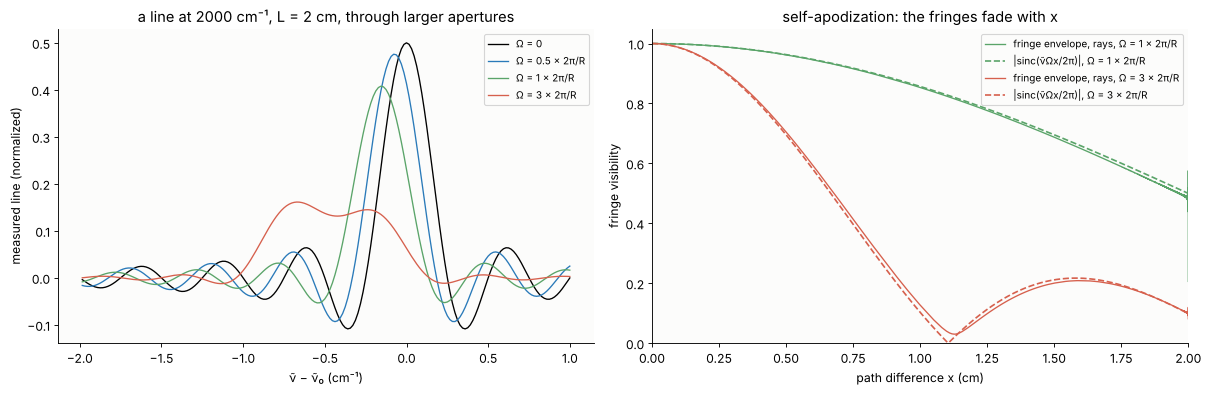

Jacquinot solid angle at R = 6628: 9.48e-04 sr, a cone of half angle 1.00°


In [9]:
nu0 = 2000.0
L = 2.0
xs1 = np.arange(-int(L/DX), int(L/DX) + 1)*DX
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
R_res = nu0/(1.207/(2*L))
for k, (frac, c) in enumerate(((0.0, "k"), (0.5, BLUE), (1.0, GREEN), (3.0, RED))):
    Om = frac*2*np.pi/R_res
    n_rays = 400
    cos_t = 1 - rng.uniform(0, Om/(2*np.pi), n_rays) if Om > 0 else np.ones(1)
    I_ap = np.mean(np.cos(2*np.pi*nu0*np.outer(cos_t, xs1)), axis=0)
    nu, S = spc.fts_spectrum(xs1, I_ap, "boxcar", n_fft=16*len(xs1))
    sel = (nu > nu0 - 2) & (nu < nu0 + 1)
    lab = "Ω = 0" if frac == 0 else "Ω = {:g} × 2π/R".format(frac)
    ax[0].plot(nu[sel] - nu0, S[sel]/2/(2*L), color=c, lw=1.2, label=lab)
    if frac > 0:
        shift_mc = np.sum((nu[sel] - nu0)*S[sel])/np.sum(S[sel])
        print("{:12s}: centroid shift {:+.4f} cm⁻¹ (−ν̃Ω/4π = {:+.4f}), FWHM {:.3f} cm⁻¹ (resolution {:.3f})".format(
            lab, shift_mc, -nu0*Om/(4*np.pi), spc.fwhm(nu[sel], S[sel]), 1.207/(2*L)))
    if frac in (1.0, 3.0):
        env = np.abs(hilbert(I_ap))
        ax[1].plot(xs1[xs1 >= 0], env[xs1 >= 0], color=c, lw=1.2, label="fringe envelope, rays, " + lab)
        xx = np.linspace(0, L, 400)
        ax[1].plot(xx, np.abs(np.sinc(nu0*Om*xx/(2*np.pi))), color=c, lw=1.5, ls="--",
                   label="|sinc(ν̃Ωx/2π)|, " + lab)
ax[0].set_xlabel("ν̃ − ν̃₀ (cm⁻¹)")
ax[0].set_ylabel("measured line (normalized)")
ax[0].set_title("a line at 2000 cm⁻¹, L = 2 cm, through larger apertures")
ax[0].legend(fontsize=9)
ax[1].set_xlim(0, L)
ax[1].set_ylim(0, 1.05)
ax[1].set_xlabel("path difference x (cm)")
ax[1].set_ylabel("fringe visibility")
ax[1].set_title("self-apodization: the fringes fade with x")
ax[1].legend(fontsize=9)
plt.show()
print("Jacquinot solid angle at R = {:.0f}: {:.2e} sr, a cone of half angle {:.2f}°".format(
    R_res, spc.jacquinot_solid_angle(R_res), np.degrees(np.sqrt(spc.jacquinot_solid_angle(R_res)/np.pi))))

The rays reproduce the closed form: the line moves by
$-\tilde\nu\Omega/4\pi$ (−0.151 against −0.156 cm⁻¹ from 400 rays at
$\Omega = 2\pi/R$), and the fringe envelope follows
$|\mathrm{sinc}(\tilde\nu\Omega x/2\pi)|$. At half the Jacquinot solid
angle the line is hardly wider than the instrument line shape; at the
Jacquinot limit it is 11 % wider; at three times the limit the fringes vanish
at $x = 1.1$ cm, the line is a broad trapezoid (0.85 cm⁻¹ instead of 0.30)
and the resolution is gone. The shift is a systematic error of the
wavenumber scale, which an instrument corrects with the known solid angle
of its J-stop. For a resolving power of 6600, the J-stop may pass a cone
of 1° half angle, about 100 times the solid angle that a grating spectrometer's
slit would pass at the same resolution (next section).

## 6. The Jacquinot and Fellgett advantages

**Étendue (Jacquinot).** A spectrometer collects the power
$P = L_\lambda\,G\,\delta\lambda$ from an extended source of spectral
radiance $L_\lambda$, where $G = A\Omega$ is its étendue (notebook 83). For
a grating spectrometer in Littrow with a collimator of focal length $f$,
a slit of width $w$ and height $h$, the resolving power
$R = 2f\tan\theta_B/w$ fixes the slit width and the étendue is
$G_\mathrm{grating} = A\,wh/f^2$. An FTS with the same beam area $A$ may use
$\Omega = 2\pi/R$, so

$$\frac{G_\mathrm{FTS}}{G_\mathrm{grating}} = \frac{2\pi/R}{wh/f^2}
  = \frac{\pi f}{h\tan\theta_B},$$

independent of $R$: with a slit $f/20$ high and a 30° blaze, about 110.

**Multiplex (Fellgett).** A scanning grating spectrometer with one
detector measures the $M$ spectral elements one after another, each
for $T/M$; an FTS sees all of them all the time. If the noise is the
detector's own (constant, independent of the light: the thermal detectors
and photoconductors of the infrared), this gains $\sqrt M$ in signal-to-noise,
less a factor of order 2 for the light the Michelson sends back to the source
and for the half of the signal that is unmodulated. If the noise is the
photon noise of the light itself (visible light on a photomultiplier),
the FTS also collects the photon noise of all elements in every sample,
and the advantage is gone. The Monte Carlo below measures the same flat
spectrum of $M$ elements both ways, with the same total time and source.

R = 10000: slit 57.7 µm × 25 mm at f = 500 mm, solid angle of the slit 5.77e-06 sr, Jacquinot stop 6.28e-04 sr: ratio 109 (π f/(h tan θ) = 109)


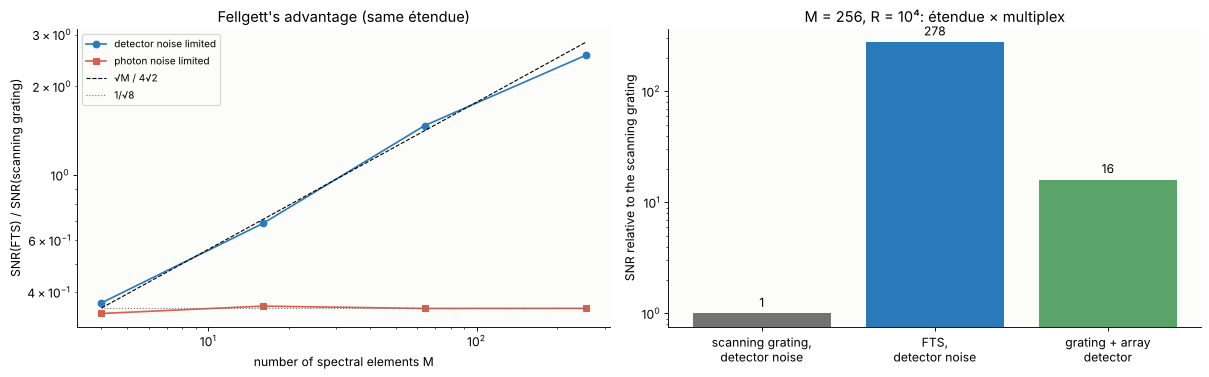

M =    4: detector noise gain  0.37 (√M/4√2 =  0.35), photon noise gain 0.34 (1/√8 = 0.35)
M =   16: detector noise gain  0.69 (√M/4√2 =  0.71), photon noise gain 0.36 (1/√8 = 0.35)
M =   64: detector noise gain  1.47 (√M/4√2 =  1.41), photon noise gain 0.35 (1/√8 = 0.35)
M =  256: detector noise gain  2.55 (√M/4√2 =  2.83), photon noise gain 0.35 (1/√8 = 0.35)


In [10]:
f_coll, h_slit, blaze = 500.0, 25.0, np.radians(30.0)
R_j = 1e4
w_slit = 2*f_coll*np.tan(blaze)/R_j
G_ratio = (2*np.pi/R_j)/(w_slit*h_slit/f_coll**2)
print("R = {:.0f}: slit {:.1f} µm × {:.0f} mm at f = {:.0f} mm, solid angle of the slit {:.2e} sr, "
      "Jacquinot stop {:.2e} sr: ratio {:.0f} (π f/(h tan θ) = {:.0f})".format(
          R_j, w_slit*1e3, h_slit, f_coll, w_slit*h_slit/f_coll**2, 2*np.pi/R_j, G_ratio,
          np.pi*f_coll/(h_slit*np.tan(blaze))))


def snr_scanning(M, flux, sigma_det, T=1.0, trials=400):
    """Scanning monochromator: element i for T/M, detector noise sigma_det per sqrt(time)."""
    t = T/M
    signal = flux*t
    meas = signal + np.sqrt(signal)*rng.standard_normal((trials, M)) \
        + sigma_det*np.sqrt(t)*rng.standard_normal((trials, M))
    return np.mean(meas.mean(axis=0)/meas.std(axis=0))


def snr_fts(M, flux, sigma_det, T=1.0, trials=400):
    """FTS: 4M samples of the interferogram of M flat elements (integer wavenumbers 1..M)
    in the total time T. Half the power goes back to the source, half of the rest is
    unmodulated: I = flux t (M + sum cos)/4. The spectrum is the exact DFT."""
    n = 4*M
    x = np.arange(n)
    k = np.arange(1, M + 1)
    t = T/n
    I = 0.25*flux*t*(M + np.sum(np.cos(2*np.pi*np.outer(x, k)/n), axis=1))
    I = np.clip(I, 0, None)
    meas = I + np.sqrt(I)*rng.standard_normal((trials, n)) \
        + sigma_det*np.sqrt(t)*rng.standard_normal((trials, n))
    spec = np.fft.rfft(meas, axis=1).real[:, 1:M + 1]
    return np.mean(spec.mean(axis=0)/spec.std(axis=0))


Ms = np.array([4, 16, 64, 256])
res = {"detector": ([], []), "photon": ([], [])}
for M in Ms:
    res["detector"][0].append(snr_scanning(M, 1e3, 1e3))
    res["detector"][1].append(snr_fts(M, 1e3, 1e3))
    res["photon"][0].append(snr_scanning(M, 1e6, 0.0))
    res["photon"][1].append(snr_fts(M, 1e6, 0.0))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
r_det = np.array(res["detector"][1])/np.array(res["detector"][0])
r_ph = np.array(res["photon"][1])/np.array(res["photon"][0])
ax[0].loglog(Ms, r_det, "o-", color=BLUE, label="detector noise limited")
ax[0].loglog(Ms, r_ph, "s-", color=RED, label="photon noise limited")
ax[0].loglog(Ms, np.sqrt(Ms)/(4*np.sqrt(2)), "k--", lw=1, label="√M / 4√2")
ax[0].loglog(Ms, np.full(len(Ms), 1/np.sqrt(8)), ":", color=GREY, lw=1, label="1/√8")
ax[0].set_xlabel("number of spectral elements M")
ax[0].set_ylabel("SNR(FTS) / SNR(scanning grating)")
ax[0].set_title("Fellgett's advantage (same étendue)")
ax[0].legend(fontsize=9)
# combined: the FTS also has the larger étendue
labels_b = ["scanning grating,\ndetector noise", "FTS,\ndetector noise", "grating + array\ndetector"]
M_ex = 256
gain_fell = r_det[-1]
vals = [1.0, gain_fell*G_ratio, np.sqrt(M_ex)]
ax[1].bar(labels_b, vals, color=[GREY, BLUE, GREEN])
ax[1].set_yscale("log")
ax[1].set_ylabel("SNR relative to the scanning grating")
ax[1].set_title("M = 256, R = 10⁴: étendue × multiplex")
for i, v in enumerate(vals):
    ax[1].text(i, v*1.15, "{:.0f}".format(v), ha="center")
plt.show()
for M, a, b in zip(Ms, r_det, r_ph):
    print("M = {:4d}: detector noise gain {:5.2f} (√M/4√2 = {:5.2f}), photon noise gain {:.2f} (1/√8 = 0.35)".format(
        M, a, np.sqrt(M)/(4*np.sqrt(2)), b))

With a 500 mm collimator, a slit 25 mm high and a 30° blaze, the
grating spectrometer at $R = 10^4$ needs a 58 µm slit and accepts
$5.8\times10^{-6}$ sr. The FTS accepts $6.3\times10^{-4}$ sr, 109 times more
light from the same extended source, exactly $\pi f/(h\tan\theta_B)$.

The Monte Carlo confirms the two regimes. With detector noise the
signal-to-noise ratio of the FTS grows as $\sqrt M/(4\sqrt2)$ against a
scanning monochromator, where the 4 collects the light lost to the
source and to the unmodulated half and the $\sqrt2$ the noise of the
real part of the transform. The FTS breaks even at about 30 elements and
gains 2.6 at 256. With photon noise it stays at $1/\sqrt8 = 0.35$
whatever $M$: the FTS loses, because every sample carries the photon noise
of the whole spectrum. Combined with the étendue gain, an FTIR measuring
256 elements with detector noise is about 280 times better than a scanning
grating instrument. That decided the infrared, where detectors are noisy.
In the visible, photon noise rules and silicon array detectors give a grating
spectrometer its own multiplex gain ($\sqrt M$, all elements at once
without the FTS penalty), which is why visible spectrometers are dispersive.

## Summary

- **Interferogram:** the cosine transform of the spectrum. The centre
  burst is a few µm wide; the spectral detail lives in weak echoes far out
  (the CO₂ line comb at multiples of $1/4B = 0.64$ cm).
- **Resolution:** a scan to $\pm L$ convolves the spectrum with the
  instrument line shape, FWHM $1.207/(2L)$ for the boxcar with −22 %
  lobes. Apodization (Norton–Beer medium: 1.69/(2L), −1.4 %) trades
  resolution for clean line shapes. Zero filling interpolates; only a longer
  scan resolves.
- **Sampling:** at the fringes of a He-Ne laser, Nyquist 7899 cm⁻¹ (once
  per fringe), aliasing beyond. A periodic position error $a$ makes ghosts
  of relative amplitude $\pi\tilde\nu a$ ($6.3\times10^{-3}$ for 10 nm at
  2000 cm⁻¹), which laser triggering removes.
- **Phase:** one-sided scans need Mertz phase correction (−0.3 % ± 0.4 %
  here). The uncorrected cosine transform was 40 % low, and the
  magnitude spectrum is biased by the noise.
- **Aperture:** off-axis rays shift a line by $-\tilde\nu\Omega/4\pi$ and
  broaden it by $\tilde\nu\Omega/2\pi$; Jacquinot's stop
  $\Omega = 2\pi/R$ keeps the broadening below the resolution.
- **Advantages:** étendue $\pi f/(h\tan\theta_B) \approx 100$ times that
  of a grating spectrometer; multiplex $\sqrt M/(4\sqrt2)$ with detector
  noise, $1/\sqrt8$ (a loss) with photon noise, which leaves the infrared
  to FTIR and the visible to gratings with array detectors.

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 12 s


## References

- P. R. Griffiths and J. A. de Haseth, *Fourier Transform Infrared
  Spectrometry*, 2nd ed., Wiley (2007).
- R. J. Bell, *Introductory Fourier Transform Spectroscopy*, Academic
  Press (1972).
- J. Kauppinen and J. Partanen, *Fourier Transforms in Spectroscopy*,
  Wiley-VCH (2001).
- P. B. Fellgett, "On the ultimate sensitivity and practical performance
  of radiation detectors", J. Opt. Soc. Am. 39, 970–976 (1949).
- P. Jacquinot, "The luminosity of spectrometers with prisms, gratings, or
  Fabry–Perot etalons", J. Opt. Soc. Am. 44, 761–765 (1954).
- L. Mertz, "Auxiliary computation for Fourier spectrometry", Infrared
  Phys. 7, 17–23 (1967).
- R. H. Norton and R. Beer, "New apodizing functions for Fourier
  spectrometry", J. Opt. Soc. Am. 66, 259–264 (1976); erratum 67, 419
  (1977).
- J. Connes and P. Connes, "Near-infrared planetary spectra by Fourier
  spectroscopy", J. Opt. Soc. Am. 56, 896–910 (1966).